# ДЗ 2. Классификация МРТ-изображений (5 классов) — решение

Задача: по изображению определить один из 5 классов (`class_0` ... `class_4`). Метрика — Accuracy; порог для положительной оценки — Public Accuracy ≥ 0.85.

**Итоговое решение** (CNN, обученная с нуля из `nn.Conv2d` / `BatchNorm2d` / `Linear` / активаций / пулинга / `Dropout`):
1. Данные: серые изображения → 1 канал, resize (bilinear), нормализация по mean/std train.
2. Сравниваются четыре конфигурации на validation: CNN из учебного ноутбука без аугментаций, собственная ResNet без аугментаций и ResNet с аугментациями (поворот, масштаб, сдвиг, hflip, яркость/контраст) и ResNet с более сильными аугментациями (плюс random erasing). Лучшая выбирается **по validation Accuracy** (с TTA).
3. Рецепт: AdamW + OneCycle, label smoothing 0.1, batch 32, предсказание по последней эпохе, TTA (оригинал + hflip).
4. Ансамбль из нескольких seed-ов на validation, затем (опционально, флаг `USE_PL`) псевдо-лейблинг на val/test.
5. Финал: ансамбль из 5 моделей выбранной конфигурации, обученных на **train+val** (шаг описан отдельно: после него качество на val уже не независимая оценка), усреднение softmax с TTA → `submission.csv`.

Используются только выданные данные; внешних данных и готовых сетей/весов нет.

**Режим FAST.** `FAST = True` — быстрая проверка, что весь ноутбук исполняется без ошибок (img 64, 2 эпохи, по 2 модели на этап). Результаты в этом режиме бессмысленны; для сдачи `FAST = False`.

Полный прогон ≈ 2.3 ч на Apple M4 (MPS); на CPU — значительно дольше.

## Настройки

In [1]:
import glob
import hashlib
import math
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

# Единственное, что нужно поменять: путь к папке mri_classification_dataset (train/ val/ test/ sample_submission.csv)
DATA_DIR = "../mri_classification_dataset"
assert os.path.isdir(os.path.join(DATA_DIR, "train")), f"не найден датасет: {os.path.abspath(DATA_DIR)}"

SEED = 42
FAST = False          # True - только проверка работоспособности (см. шапку)
NUM_CLASSES = 5
UNIQUE_THR = 0.98        # порог корреляции для маски почти-дублей

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch, "mps") and hasattr(torch.mps, "manual_seed"):
        torch.mps.manual_seed(seed)


set_seed(SEED)
print("device:", DEVICE, "| torch", torch.__version__, "| FAST =", FAST)

device: mps | torch 2.14.1 | FAST = False


**О воспроизводимости.** На MPS/CUDA часть операций (свёртки, `grid_sample`, атомарные сложения) недетерминирована, поэтому повторный запуск может отличаться на единичных изображениях — в основном там, где ансамбль не уверен. CSV, отправленный в контест, — это результат выполнения именно этого ноутбука; sha256 файла печатается в конце.

## Конфигурация экспериментов и финала

Все гиперпараметры собраны здесь. `DEFAULTS` — рецепт по умолчанию; конфиги `EXPERIMENTS` переопределяют его части.
`tta=None` означает «TTA включён, если есть аугментации». Номер seed-а конфигов задаёт инициализацию и порядок батчей.

Seed-ы получаются от `SEED`: эксперименты - `SEED`, val-ансамбль - `SEED+i`, PL-модель на val - `SEED+1000`, «разметчики» PL - `SEED+200+i`, финальные модели - `SEED+300+i`.

In [2]:
DEFAULTS = dict(
    model="resnet", width=32, blocks=[2, 2, 2, 2], stem_pool=False, dropout=0.2, img=224, epochs=60,
    bs=32, lr=2e-3, wd=5e-4, sched="onecycle", ls=0.1,
    aug=dict(rot=15, scale=0.15, shift=0.08, bc=0.2, erase=0.0),
    seed=SEED, tta=None,
    eval_every=5,   # val-оценка каждые eval_every эпох и на всех последних 5
)


def make_cfg(name, **kw):
    cfg = {**DEFAULTS, **kw, "name": name}
    if cfg["tta"] is None:
        cfg["tta"] = bool(cfg["aug"])
    return cfg


# Порядок: от простого к сложному (важно при равенстве val-метрик, см. "Выбор модели")
EXPERIMENTS = [
    make_cfg("tut_noaug", model="tutorial", aug=None, epochs=40, img=224, ls=0.0, sched="cosine",
             lr=1e-3, wd=0.0, dropout=0.0, tta=False),
    make_cfg("res_noaug", aug=None, epochs=40, tta=False),
    make_cfg("res_aug", epochs=60),
    make_cfg("res_aug_strong", epochs=60, aug=dict(rot=20, scale=0.2, shift=0.1, bc=0.3, erase=0.25)),
]

# Параметры ансамбля / псевдо-лейблинга / финала
N_SEEDS_VAL = 3                  # моделей в val-ансамбле (включая seed 0 из экспериментов)
USE_PL = False                      # псевдо-лейблинг на val/test (проверка на val + финал)
PL_THR = 0.9                       # порог средней max-prob; дополнительно нужно согласие argmax всех моделей
N_SEEDS_PL_LABELERS = 3            # (USE_PL) моделей на train+val, дающих псевдо-метки test
N_SEEDS_FINAL = 5                  # финальных моделей на train+val (+PL test)

if FAST:
    N_SEEDS_VAL, N_SEEDS_FINAL, N_SEEDS_PL_LABELERS = 2, 2, 2
    PL_THR = 0.0   # чтобы ветка PL реально отбирала примеры после 2 эпох
    for c in EXPERIMENTS:
        c["img"], c["epochs"] = 64, 2
print("USE_PL =", USE_PL, "| PL_THR =", PL_THR, "| N_SEEDS_VAL / PL_LABELERS / FINAL =",
      N_SEEDS_VAL, N_SEEDS_PL_LABELERS, N_SEEDS_FINAL)

USE_PL = False | PL_THR = 0.9 | N_SEEDS_VAL / PL_LABELERS / FINAL = 3 3 5


## Загрузка данных

Структура: `train/class_k/*.jpg`, `val/class_k/*.jpg` (метка `k` берётся из имени папки), `test/*.jpg` без меток. Файлы сортируются по имени, порядок детерминирован. Картинки приводятся к одному каналу и размеру `img` (bilinear) и целиком хранятся в памяти как `uint8`.

In [3]:
def list_split(split):
    """Возвращает (пути, метки или None, id)."""
    if split == "test":
        paths = sorted(glob.glob(os.path.join(DATA_DIR, "test", "*.jpg")))
        labels = None
    else:
        paths, labels = [], []
        for k in range(NUM_CLASSES):
            ps = sorted(glob.glob(os.path.join(DATA_DIR, split, f"class_{k}", "*.jpg")))
            paths += ps
            labels += [k] * len(ps)
    ids = [os.path.splitext(os.path.basename(p))[0] for p in paths]
    return paths, labels, ids


def load_split(split, S):
    """-> dict(x=uint8 [N,1,S,S], y=int64 [N] или None, ids, orig=исходный размер [N], gray=[N] bool)."""
    paths, labels, ids = list_split(split)
    xs, orig, gray = [], [], []
    for p in paths:
        im = Image.open(p)
        orig.append(im.size[0])
        if im.mode == "L":
            gray.append(True)
        else:
            a = np.asarray(im.convert("RGB"))
            gray.append(bool((a[..., 0] == a[..., 1]).all() and (a[..., 0] == a[..., 2]).all()))
        im = im.convert("L")
        xs.append(np.asarray(im.resize((S, S), Image.BILINEAR), dtype=np.uint8))
    return dict(
        x=torch.from_numpy(np.stack(xs))[:, None].contiguous(),
        y=None if labels is None else torch.tensor(labels, dtype=torch.long),
        ids=ids,
        orig=torch.tensor(orig),
        gray=torch.tensor(gray),
    )


_DATA_CACHE = {}


def get_data(S):
    if S not in _DATA_CACHE:
        _DATA_CACHE[S] = {s: load_split(s, S) for s in ("train", "val", "test")}
    return _DATA_CACHE[S]


def norm_stats(S):
    """mean/std по train (в долях от 255) для размера S."""
    x = get_data(S)["train"]["x"].float() / 255
    return x.mean().item(), x.std().item()


S0 = EXPERIMENTS[0]["img"]
d0 = get_data(S0)
for s in ("train", "val", "test"):
    print(f"{s}: {len(d0[s]['x'])} изображений, исходные размеры: "
          f"{dict(zip(*[t.tolist() for t in torch.unique(d0[s]['orig'], return_counts=True)]))}")
for s in ("train", "val"):
    print(f"{s}: распределение классов", torch.bincount(d0[s]["y"], minlength=NUM_CLASSES).tolist())

train: 1390 изображений, исходные размеры: {256: 476, 512: 914}
val: 298 изображений, исходные размеры: {256: 104, 512: 194}
test: 300 изображений, исходные размеры: {256: 109, 512: 191}
train: распределение классов [278, 279, 277, 278, 278]
val: распределение классов [60, 59, 60, 60, 59]


## Краткий EDA

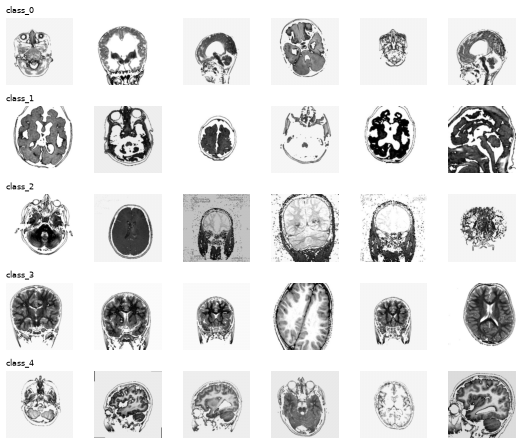

все изображения серые (каналы RGB совпадают): True


In [4]:
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(9, 7.5), dpi=60)
for k in range(NUM_CLASSES):
    idx = (d0["train"]["y"] == k).nonzero().flatten()[:6]
    for j, i in enumerate(idx):
        axes[k, j].imshow(d0["train"]["x"][i, 0], cmap="gray", vmin=0, vmax=255)
        axes[k, j].axis("off")
    axes[k, 0].set_title(f"class_{k}", fontsize=9, loc="left")
plt.tight_layout()
plt.show()

print("все изображения серые (каналы RGB совпадают):",
      all(bool(d0[s]["gray"].all()) for s in ("train", "val", "test")))

### Почти-дубли между train и val/test

В данных есть почти-копии одних и тех же снимков. Для каждого изображения val/test считается корреляция его нормализованной уменьшенной копии 16×16 с каждым изображением train. Если максимум корреляции > 0.98, изображение считается почти-дублем train. Помимо общей accuracy на val ниже считается `val_unique` — accuracy на val-изображениях **без** почти-дубля в train: она показывает обобщение на действительно новые снимки, а не запоминание. Выбор модели идёт по общей val accuracy, `val_unique` используется при равенстве и как контроль.

In [5]:
def small_vectors(split):
    paths, _, _ = list_split(split)
    v = np.stack([
        np.asarray(Image.open(p).convert("L").resize((16, 16), Image.BILINEAR), dtype=np.float32).ravel()
        for p in paths
    ])
    v -= v.mean(1, keepdims=True)
    v /= np.linalg.norm(v, axis=1, keepdims=True) + 1e-8
    return v


v_tr = small_vectors("train")
y_tr_np = d0["train"]["y"].numpy()
UNIQUE = {}
for split in ("val", "test"):
    corr = small_vectors(split) @ v_tr.T
    mx, nn_idx = corr.max(1), corr.argmax(1)
    dup = mx >= UNIQUE_THR
    UNIQUE[split] = torch.from_numpy(~dup)
    msg = f"{split}: почти-дубль в train есть у {dup.mean():.1%} изображений"
    if split == "val":
        agree = (y_tr_np[nn_idx][dup] == d0["val"]["y"].numpy()[dup]).mean()
        msg += f"; у пар val-train метки совпадают в {agree:.1%} случаев"
    print(msg)
VAL_UNIQUE = UNIQUE["val"].numpy()
print("val_unique: изображений", int(VAL_UNIQUE.sum()), "из", len(VAL_UNIQUE))

val: почти-дубль в train есть у 26.5% изображений; у пар val-train метки совпадают в 100.0% случаев
test: почти-дубль в train есть у 26.0% изображений
val_unique: изображений 219 из 298


## Аугментации

Все аугментации выполняются батчем на устройстве:
- **hflip** (случайное отражение), **поворот** ±`rot`°, **масштаб** ±`scale`, **сдвиг** ±`shift` от размера — одна аффинная матрица (`affine_grid` + `grid_sample`), края заполняются нулями;
- **яркость/контраст** (`bc`): контраст ×(1±bc) относительно среднего, смещение яркости ±bc/2;
- **random erasing** (`erase`, вероятность) — прямоугольник заполняется средним значением изображения (в базовых конфигах выключено).

Зачем: 1390 train-картинок мало, сеть без аугментаций быстро переобучается (train acc = 1.0). Аугментации имитируют вариации положения/экспозиции снимка. Те же преобразования (hflip) используются в TTA.

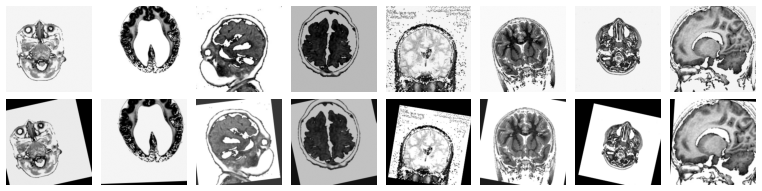

In [6]:
def _affine(x, theta):
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)


def shift_images(x, dx, dy):
    """Сдвиг на доли размера (dx, dy — тензоры [B] долей ширины/высоты)."""
    B = x.shape[0]
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0] = 1
    theta[:, 1, 1] = 1
    theta[:, 0, 2] = -2 * dx
    theta[:, 1, 2] = -2 * dy
    return _affine(x, theta)


AUG_COLS = 12  # колонок случайных чисел на объект: flip, ang, scale, shift(2), c, b, area, ratio, y0, x0, gate


def aug_params(n, gen):
    """Все случайные числа аугментаций одним тензором [n, AUG_COLS] (CPU-генератор -> device одним переносом)."""
    return torch.rand(n, AUG_COLS, generator=gen).to(DEVICE)


def augment(x, cfg, gen, r=None):
    """x: float [B,1,S,S] в [0,1] на device. cfg: dict(rot, scale, shift, bc, erase, flip). Сила 0 -> отключено.
    r: готовые случайные числа [B, AUG_COLS] (aug_params), иначе берутся из CPU-генератора gen."""
    B, _, H, W = x.shape
    dev = x.device
    if r is None:
        r = aug_params(B, gen)

    if cfg.get("flip", True):
        flip = (r[:, 0] < 0.5).float() * -2 + 1  # -1 -> отразить по горизонтали
    else:
        flip = torch.ones(B, device=dev)
    ang = (r[:, 1] * 2 - 1) * math.radians(cfg.get("rot", 0))
    sc = 1 + (r[:, 2] * 2 - 1) * cfg.get("scale", 0)
    sh = (r[:, 3:5] * 2 - 1) * cfg.get("shift", 0) * 2
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = torch.cos(ang) / sc * flip
    theta[:, 0, 1] = -torch.sin(ang) / sc
    theta[:, 1, 0] = torch.sin(ang) / sc * flip
    theta[:, 1, 1] = torch.cos(ang) / sc
    theta[:, :, 2] = sh
    x = _affine(x, theta)

    bc = cfg.get("bc", 0)
    if bc > 0:
        mean = x.mean(dim=(1, 2, 3), keepdim=True)
        c = 1 + (r[:, 5].view(B, 1, 1, 1) * 2 - 1) * bc
        b = (r[:, 6].view(B, 1, 1, 1) * 2 - 1) * bc * 0.5
        x = ((x - mean) * c + mean + b).clamp(0, 1)

    er = cfg.get("erase", 0)
    if er > 0:
        area = 0.02 + r[:, 7] * 0.13
        ratio = torch.exp((r[:, 8] * 2 - 1) * math.log(3))
        h = (area * ratio).sqrt().clamp(max=1) * H
        w = (area / ratio).sqrt().clamp(max=1) * W
        y0 = r[:, 9] * (H - h)
        x0 = r[:, 10] * (W - w)
        ys = torch.arange(H, device=dev).view(1, H, 1)
        xs = torch.arange(W, device=dev).view(1, 1, W)
        m = (ys >= y0.view(B, 1, 1)) & (ys < (y0 + h).view(B, 1, 1)) & \
            (xs >= x0.view(B, 1, 1)) & (xs < (x0 + w).view(B, 1, 1))
        m = m & (r[:, 11] < er).view(B, 1, 1)
        x = torch.where(m[:, None], x.mean(dim=(1, 2, 3), keepdim=True).expand_as(x), x)
    return x


# Демонстрация: верхний ряд - исходные, нижний - аугментированные
aug_demo = next(c["aug"] for c in EXPERIMENTS if c["aug"])
xb = d0["train"]["x"][::170][:8].to(DEVICE).float() / 255
xa = augment(xb, aug_demo, torch.Generator().manual_seed(SEED))
fig, axes = plt.subplots(2, len(xb), figsize=(1.6 * len(xb), 3.4), dpi=60)
for j in range(len(xb)):
    axes[0, j].imshow(xb[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(xa[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[0, j].axis("off")
    axes[1, j].axis("off")
plt.tight_layout()
plt.show()

## Модели

Обе сети собраны вручную из базовых слоёв.

- **TutorialCNN** — CNN из учебного ноутбука: 3 блока `Conv3x3 → ReLU → MaxPool` (32/64/128 каналов) и полносвязная голова 512 → 5. Отличия: вход 1 канал, 5 классов, перед `Flatten` стоит `AdaptiveAvgPool2d((4, 4))` (в учебном ноутбуке картинки 32×32 дают 4×4 после трёх пулингов; при другом размере входа размер приводится к 4×4), `Dropout` в учебной модели нет (здесь 0).
- **ResNet** — своя остаточная сеть: стем `Conv3x3 stride 2 + BN + ReLU`, 4 стадии по 2 `BasicBlock` (каналы 32 → 64 → 128 → 256, downsample первым блоком стадии), skip connections (с 1×1-проекцией при смене размерности), глобальный average pooling, `Dropout` и `Linear`. Инициализация Kaiming.

In [7]:
class TutorialCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.0):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.fc_layers = nn.Sequential(
            nn.Linear(128 * 4 * 4, 512), nn.ReLU(), nn.Dropout(dropout), nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_layers(x.flatten(1))


class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.short = None
        if stride != 1 or cin != cout:
            self.short = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + (x if self.short is None else self.short(x)))


class ResNet(nn.Module):
    def __init__(self, width=32, blocks=(2, 2, 2, 2), stem_pool=False, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        stem = [nn.Conv2d(1, width, 3, 2, 1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        if stem_pool:
            stem.append(nn.MaxPool2d(3, 2, 1))
        self.stem = nn.Sequential(*stem)
        layers, cin = [], width
        for i, n in enumerate(blocks):
            cout = width * 2 ** i
            for j in range(n):
                layers.append(BasicBlock(cin, cout, (1 if i == 0 else 2) if j == 0 else 1))
                cin = cout
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(self.drop(self.pool(x).flatten(1)))


def build_model(cfg):
    if cfg["model"] == "tutorial":
        m = TutorialCNN(dropout=cfg["dropout"])
    else:
        m = ResNet(cfg["width"], tuple(cfg["blocks"]), cfg["stem_pool"], cfg["dropout"])
    # channels_last не используем: на MPS он заметно медленнее
    return m.to(DEVICE)


for c in EXPERIMENTS:
    print(f"{c['name']}: параметров {sum(p.numel() for p in build_model(c).parameters()):,}")

tut_noaug: параметров 1,144,325
res_noaug: параметров 2,795,749
res_aug: параметров 2,795,749
res_aug_strong: параметров 2,795,749


## Обучение и предсказание

`train_model` обучает сеть с нуля: AdamW, расписание OneCycle (или cosine с warmup), `CrossEntropyLoss` с label smoothing, батчи из данных в памяти, аугментации на лету. Если передан val, он оценивается раз в `eval_every` эпох и на каждой из последних 5 эпох — только для кривых; **итоговая модель — последняя эпоха** (best-checkpoint не выбирается, чтобы val не просачивался в обучение).

`predict` возвращает softmax; при `tta=True` усредняются оригинал и горизонтальное отражение.

In [8]:
def make_optimizer(params, cfg):
    try:
        return torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["wd"], fused=True)
    except (RuntimeError, ValueError):
        return torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["wd"])


@torch.no_grad()
def predict(model, x_u8, tta=False, bs=64):
    """softmax [N,5] (numpy). tta: False | True (оригинал+hflip) | 'full' (+ сдвиги +-4%)."""
    model.eval()
    mean, std = model.norm
    out = []
    for i in range(0, len(x_u8), bs):
        x = x_u8[i:i + bs].to(DEVICE).float() / 255
        views = [x]
        if tta:
            views.append(x.flip(3))
        if tta == "full":
            z = torch.zeros(len(x), device=DEVICE)
            for dx, dy in ((0.04, 0), (-0.04, 0), (0, 0.04), (0, -0.04)):
                views.append(shift_images(x, z + dx, z + dy))
        p = 0
        for v in views:
            p = p + F.softmax(model((v - mean) / std), 1)
        out.append((p / len(views)).cpu())
    return torch.cat(out).numpy()


def train_model(cfg, x_train, y_train, x_val=None, y_val=None, val_unique=None, verbose=True):
    """Обучает модель с нуля. x_*: uint8 [N,1,S,S] (CPU), y_*: int64. -> (model, hist).
    hist: dict(val=[[эпоха, acc]], val_unique=[[эпоха, acc]]) - кривые по val (если он передан)."""
    set_seed(cfg["seed"])
    gen = torch.Generator().manual_seed(cfg["seed"])
    mean, std = norm_stats(cfg["img"])  # по train, даже если в обучение добавлены val/PL
    mean_t, std_t = torch.tensor(mean, device=DEVICE), torch.tensor(std, device=DEVICE)

    xtr, ytr = x_train.to(DEVICE), y_train.to(DEVICE)
    N, bs, epochs = len(xtr), cfg["bs"], cfg["epochs"]
    steps_ep = N // bs

    model = build_model(cfg)
    model.norm = (mean_t, std_t)
    opt = make_optimizer(model.parameters(), cfg)
    if cfg["sched"] == "onecycle":
        sched = torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=cfg["lr"], total_steps=steps_ep * epochs, pct_start=0.15)
    else:
        warm, total = 3 * steps_ep, steps_ep * epochs
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s: (s + 1) / warm if s < warm
            else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["ls"])

    hist = dict(val=[], val_unique=[])
    yv = None if y_val is None else y_val.numpy()
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(N, generator=gen).to(DEVICE)
        aug_r = aug_params(steps_ep * bs, gen).view(steps_ep, bs, AUG_COLS) if cfg["aug"] else None
        loss_sum = torch.zeros((), device=DEVICE)
        correct = torch.zeros((), device=DEVICE)
        for i in range(steps_ep):
            idx = perm[i * bs:(i + 1) * bs]
            x = xtr[idx].float() / 255
            y = ytr[idx]
            if cfg["aug"]:
                x = augment(x, cfg["aug"], gen, aug_r[i])
            out = model((x - mean_t) / std_t)
            loss = crit(out, y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            loss_sum += loss.detach().float() * len(y)
            correct += (out.argmax(1) == y).sum()
        do_eval = x_val is not None and ((ep + 1) % cfg["eval_every"] == 0 or ep + 1 > epochs - 5)
        if do_eval:
            ok = predict(model, x_val).argmax(1) == yv
            hist["val"].append([ep + 1, float(ok.mean())])
            if val_unique is not None:
                hist["val_unique"].append([ep + 1, float(ok[val_unique].mean())])
        if verbose and ((ep + 1) % 5 == 0 or ep == 0 or ep + 1 == epochs):
            msg = (f"[{cfg['name']}] ep {ep + 1}/{epochs} loss {loss_sum.item() / (steps_ep * bs):.4f} "
                   f"train_acc {correct.item() / (steps_ep * bs):.4f} ")
            if do_eval:
                msg += f"val {hist['val'][-1][1]:.4f} "
            print(msg + f"t {time.time() - t0:.0f}s", flush=True)
    model.train_sec = time.time() - t0
    return model, hist

## Эксперименты на validation

Каждый конфиг обучается на **train** и оценивается на **val**: accuracy последней эпохи без TTA, с TTA (если TTA включён для конфига) и `val_unique`. Четыре конфига — от простой учебной CNN до ResNet с сильными аугментациями.

[tut_noaug] ep 1/40 loss 1.5533 train_acc 0.2987 t 5s


[tut_noaug] ep 5/40 loss 0.4155 train_acc 0.8612 val 0.8423 t 24s


[tut_noaug] ep 10/40 loss 0.1351 train_acc 0.9535 val 0.8926 t 48s


[tut_noaug] ep 15/40 loss 0.0881 train_acc 0.9644 val 0.9094 t 71s


[tut_noaug] ep 20/40 loss 0.0142 train_acc 0.9971 val 0.9430 t 96s


...

[res_aug_strong] ep 50/60 loss 0.4495 train_acc 0.9920 val 1.0000 t 623s


[res_aug_strong] ep 55/60 loss 0.4385 train_acc 0.9956 val 1.0000 t 684s


[res_aug_strong] ep 60/60 loss 0.4397 train_acc 0.9956 val 1.0000 t 749s


>>> res_aug_strong: val 1.0000, val+TTA 1.0000, val_unique 1.0000, val_nll 0.0626



,name,model,epochs,aug,tta,params,val_acc,val_acc_tta,val_unique,val_nll,minutes
0,tut_noaug,tutorial,40,False,False,1144325,0.9497,0.9497,0.9361,0.3099,3.5727
1,res_noaug,resnet,40,False,False,2795749,0.9664,0.9664,0.9543,0.2000,7.9925
2,res_aug,resnet,60,True,True,2795749,1.0000,1.0000,1.0000,0.0779,12.2379
3,res_aug_strong,resnet,60,True,True,2795749,1.0000,1.0000,1.0000,0.0626,12.4834


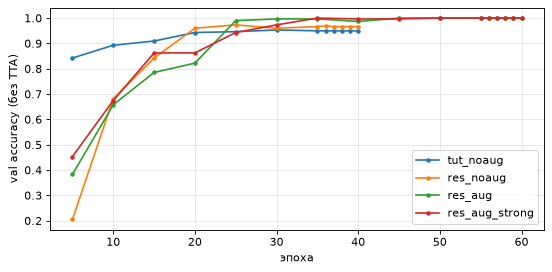

In [9]:
RESULTS = {}   # name -> dict(cfg, model, hist, val_probs, ...)
for cfg in EXPERIMENTS:
    d = get_data(cfg["img"])
    model, hist = train_model(cfg, d["train"]["x"], d["train"]["y"], d["val"]["x"], d["val"]["y"], VAL_UNIQUE)
    yv = d["val"]["y"].numpy()
    p_plain = predict(model, d["val"]["x"])
    p_tta = predict(model, d["val"]["x"], cfg["tta"]) if cfg["tta"] else p_plain
    nll = float(-np.log(np.clip(p_tta[np.arange(len(yv)), yv], 1e-12, None)).mean())
    RESULTS[cfg["name"]] = dict(
        cfg=cfg, model=model, hist=hist, val_probs=p_tta,
        val_acc=float((p_plain.argmax(1) == yv).mean()),
        val_acc_tta=float((p_tta.argmax(1) == yv).mean()),
        val_unique=float((p_tta.argmax(1) == yv)[VAL_UNIQUE].mean()),
        val_nll=nll,
        minutes=model.train_sec / 60,
        params=sum(p.numel() for p in model.parameters()),
    )
    r = RESULTS[cfg["name"]]
    print(f">>> {cfg['name']}: val {r['val_acc']:.4f}, val+TTA {r['val_acc_tta']:.4f}, val_unique {r['val_unique']:.4f}, val_nll {r['val_nll']:.4f}\n")

table = pd.DataFrame([
    dict(name=n, model=r["cfg"]["model"], epochs=r["cfg"]["epochs"], aug=bool(r["cfg"]["aug"]), tta=bool(r["cfg"]["tta"]),
         params=r["params"], val_acc=r["val_acc"], val_acc_tta=r["val_acc_tta"], val_unique=r["val_unique"],
         val_nll=r["val_nll"], minutes=r["minutes"])
    for n, r in RESULTS.items()
]).round(4)
display(table)

fig, ax = plt.subplots(figsize=(7, 3.5), dpi=80)
for n, r in RESULTS.items():
    h = np.array(r["hist"]["val"])
    ax.plot(h[:, 0], h[:, 1], marker="o", ms=3, label=n)
ax.set_xlabel("эпоха")
ax.set_ylabel("val accuracy (без TTA)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Более широкий перебор (вне ноутбука)

Более широкий перебор выполнен отдельным исследовательским скриптом `experiments.py` (не входит в сдачу; та же архитектура и рецепт обучения, обучение на train, оценка на val).

Все конфиги — ResNet ширины 32 — 2.8M параметров (res_w48 — 6.3M); tut_noaug — учебная CNN. 224 px, AdamW + OneCycle, label smoothing 0.1, batch 32, 60 эпох, TTA (оригинал + hflip), если не указано иное. Метрики — на последней эпохе.

Прогон отдельным скриптом с seed 0 (в ноутбуке seed 42), поэтому строки tut_noaug / res_noaug / res_aug / res_aug_strong отличаются от таблицы выше в пределах разброса между seed-ами.

| Конфиг | Отличие от `res_aug` | val acc | val acc (TTA) | val_unique (TTA) | val NLL (TTA) |
|---|---|---|---|---|---|
| tut_noaug | учебная CNN, без аугментаций, 40 эп., без TTA, ls 0 | 0.946 | — | 0.932 | 0.309 |
| res_noaug | без аугментаций, 40 эп., без TTA | 0.983 | — | 0.982 | 0.210 |
| res_aug | аугментации: rot 15°, scale 0.15, shift 0.08, яркость/контраст 0.2 | 1.000 | 1.000 | 1.000 | 0.081 |
| res_aug_s1 / res_aug_s2 | то же, seed 1 / 2 | 1.000 / 0.990 | 1.000 / 1.000 | 1.000 / 1.000 | 0.078 / 0.077 |
| res_aug_strong | rot 20°, scale 0.2, shift 0.1, bc 0.3, random erasing 0.25 | 1.000 | 1.000 | 1.000 | **0.065** |
| res_aug_light | rot 10°, scale 0.1, shift 0.05, bc 0.1 | 1.000 | 1.000 | 1.000 | 0.087 |
| res_w48 | ширина 48 (каналы 48→384) | 1.000 | 1.000 | 1.000 | 0.071 |
| res_img256 | 256 px | 1.000 | 0.997 | 0.995 | 0.078 |
| res_img288_pool | 288 px + maxpool в stem | 0.997 | 0.997 | 0.995 | 0.083 |
| res_e100 | 100 эпох | 0.997 | 1.000 | 1.000 | 0.080 |
| res_mixup | mixup α=0.2 | 0.997 | 1.000 | 1.000 | 0.103 |
| res_ls0 | без label smoothing (NLL несопоставим) | 0.997 | 0.997 | 0.995 | 0.007 |
| res_wd5e-3 | weight decay 5e-3 | 1.000 | 1.000 | 1.000 | 0.075 |

Выводы: аугментации — главный фактор (0.97–0.98 → 1.000 в обоих прогонах); архитектурные и регуляризационные варианты дают ту же accuracy (val насыщен), различаются только log-loss; рецепт устойчив к seed. Лучший log-loss — у сильных аугментаций, поэтому `res_aug_strong` включён в эксперименты ноутбука.

## Выбор модели

Лучшая конфигурация выбирается **по validation Accuracy** (с TTA, если он включён для конфига). Ключ сортировки: `(val_acc_tta, val_unique, -val_nll)`.

Accuracy на val (298 изображений, одна ошибка = 0.34%) насыщается: несколько конфигураций дают одинаковые значения вплоть до 1.000. Поэтому при равенстве сначала смотрим `val_unique` (качество на снимках без почти-дубля в train), а при дальнейшем равенстве решает log-loss `val_nll` = средний `-log p(истинный класс)` на тех же предсказаниях, которые идут в метрику (с TTA, если он включён): чем меньше, тем увереннее модель в правильных ответах. Сравнивать NLL корректно, потому что претенденты с ResNet обучены с одинаковым label smoothing 0.1; у `tut_noaug` label smoothing 0, его NLL несопоставим, но на выбор это не влияет, пока у него accuracy ниже.

In [10]:
names = [c["name"] for c in EXPERIMENTS]
BEST_NAME = max(names, key=lambda n: (RESULTS[n]["val_acc_tta"], RESULTS[n]["val_unique"], -RESULTS[n]["val_nll"]))
BEST = dict(RESULTS[BEST_NAME]["cfg"])
print("выбран:", BEST_NAME, "| val acc (TTA) =", round(RESULTS[BEST_NAME]["val_acc_tta"], 4),
      "| val_unique =", round(RESULTS[BEST_NAME]["val_unique"], 4),
      "| val_nll =", round(RESULTS[BEST_NAME]["val_nll"], 4))
print(BEST)

выбран: res_aug_strong | val acc (TTA) = 1.0 | val_unique = 1.0 | val_nll = 0.0626
{'model': 'resnet', 'width': 32, 'blocks': [2, 2, 2, 2], 'stem_pool': False, 'dropout': 0.2, 'img': 224, 'epochs': 60, 'bs': 32, 'lr': 0.002, 'wd': 0.0005, 'sched': 'onecycle', 'ls': 0.1, 'aug': {'rot': 20, 'scale': 0.2, 'shift': 0.1, 'bc': 0.3, 'erase': 0.25}, 'seed': 42, 'tta': True, 'eval_every': 5, 'name': 'res_aug_strong'}


## Ансамбль + TTA на validation

Честная оценка выбранного рецепта: `N_SEEDS_VAL` моделей `BEST` с разными seed-ами обучаются на train (модель №0 (seed `SEED`) уже обучена в экспериментах и переиспользуется), softmax усредняется (с TTA) → accuracy ансамбля на val.

In [11]:
dB = get_data(BEST["img"])
xtr_B, ytr_B = dB["train"]["x"], dB["train"]["y"]
xv_B, yv_B = dB["val"]["x"], dB["val"]["y"]
yv_np = yv_B.numpy()

val_models = [RESULTS[BEST_NAME]["model"]]
val_probs = [RESULTS[BEST_NAME]["val_probs"]]
for s in range(1, N_SEEDS_VAL):
    m, _ = train_model({**BEST, "seed": SEED + s}, xtr_B, ytr_B, xv_B, yv_B, VAL_UNIQUE)
    val_models.append(m)
    val_probs.append(predict(m, xv_B, BEST["tta"]))

for s, p in enumerate(val_probs):
    print(f"seed {s}: val {(p.argmax(1) == yv_np).mean():.4f}")
p_ens = np.mean(val_probs, axis=0)
ok = p_ens.argmax(1) == yv_np
VAL_ENS_ACC, VAL_ENS_UNIQUE = float(ok.mean()), float(ok[VAL_UNIQUE].mean())
print(f"ансамбль из {len(val_models)} моделей + TTA: val {VAL_ENS_ACC:.4f}, val_unique {VAL_ENS_UNIQUE:.4f}")

[res_aug_strong] ep 1/60 loss 1.5871 train_acc 0.2631 t 12s


[res_aug_strong] ep 5/60 loss 1.0569 train_acc 0.6526 val 0.5067 t 62s


[res_aug_strong] ep 10/60 loss 0.8328 train_acc 0.7922 val 0.5403 t 124s


[res_aug_strong] ep 15/60 loss 0.6913 train_acc 0.8699 val 0.8456 t 185s


[res_aug_strong] ep 20/60 loss 0.5917 train_acc 0.9302 val 0.8523 t 246s


...

[res_aug_strong] ep 45/60 loss 0.4516 train_acc 0.9935 val 0.9899 t 562s


[res_aug_strong] ep 50/60 loss 0.4431 train_acc 0.9949 val 0.9933 t 623s


[res_aug_strong] ep 55/60 loss 0.4328 train_acc 0.9985 val 1.0000 t 685s


[res_aug_strong] ep 60/60 loss 0.4350 train_acc 0.9956 val 0.9966 t 749s


seed 0: val 1.0000
seed 1: val 1.0000
seed 2: val 1.0000
ансамбль из 3 моделей + TTA: val 1.0000, val_unique 1.0000


## Псевдо-лейблинг (флаг `USE_PL`)

Идея: уверенные предсказания ансамбля для неразмеченных изображений используются как метки для дообучения. Отбираются изображения, у которых **средняя max-вероятность ≥ `PL_THR`** и **все модели ансамбля согласны по argmax**.

Проверка на val (схема трансдуктивная): ансамбль из предыдущего шага, обученный только на train, размечает val и test; одна модель `BEST` обучается на train + псевдо-размеченные val и test. Истинные метки val нигде не используются при обучении, поэтому val accuracy по истинным меткам остаётся честной оценкой (так же, как это будет для test). Если `USE_PL = False`, шаг пропускается.

**По умолчанию `USE_PL = False`**: validation насыщена (accuracy ≈ 1.0), поэтому измеримого выигрыша от псевдо-меток показать нельзя, а они несут риск закрепить ошибки модели. Ветка оставлена в ноутбуке работоспособной и проверена в режиме FAST.

In [12]:
def select_pseudo(prob_list, thr):
    """prob_list: список softmax [N,5] разных моделей -> (bool-маска, псевдо-метки)."""
    p = np.mean(prob_list, axis=0)
    am = np.stack([q.argmax(1) for q in prob_list])
    sel = (p.max(1) >= thr) & (am == am[0]).all(0)
    return torch.from_numpy(sel), torch.from_numpy(p.argmax(1))


PL_VAL = None
if USE_PL:
    xt_B = dB["test"]["x"]
    sel_v, pl_v = select_pseudo(val_probs, PL_THR)
    sel_t, pl_t = select_pseudo([predict(m, xt_B, BEST["tta"]) for m in val_models], PL_THR)
    acc_pl = float((pl_v[sel_v] == yv_B[sel_v]).float().mean()) if sel_v.any() else float("nan")
    print(f"отобрано: val {int(sel_v.sum())}/{len(sel_v)} (точность псевдо-меток по истинным {acc_pl:.4f}), "
          f"test {int(sel_t.sum())}/{len(sel_t)}")
    x_pl = torch.cat([xtr_B, xv_B[sel_v], xt_B[sel_t]])
    y_pl = torch.cat([ytr_B, pl_v[sel_v], pl_t[sel_t]])
    m_pl, _ = train_model({**BEST, "seed": SEED + 1000, "name": BEST["name"] + "_pl"}, x_pl, y_pl, xv_B, yv_B, VAL_UNIQUE)
    p_plain, p_tta = predict(m_pl, xv_B), predict(m_pl, xv_B, BEST["tta"])
    ok = p_tta.argmax(1) == yv_np
    PL_VAL = dict(val_acc=float((p_plain.argmax(1) == yv_np).mean()), val_acc_tta=float(ok.mean()),
                  val_unique=float(ok[VAL_UNIQUE].mean()))
    print(f"одна модель {BEST_NAME} + PL: val {PL_VAL['val_acc']:.4f}, val+TTA {PL_VAL['val_acc_tta']:.4f}, "
          f"val_unique {PL_VAL['val_unique']:.4f}")
    print(f"для сравнения: без PL (seed 0) val+TTA {RESULTS[BEST_NAME]['val_acc_tta']:.4f}; ансамбль без PL {VAL_ENS_ACC:.4f}")
else:
    print("USE_PL = False: шаг пропущен")

USE_PL = False: шаг пропущен


## Финальное обучение на train+val

Рецепт выбран и проверен на validation. Для итоговых предсказаний модели **переобучаются на train+val** (1688 изображений вместо 1390) с тем же числом эпох: больше данных обычно улучшает результат на test. Важно: после этого шага **val уже участвует в обучении, и качество на нём не является независимой оценкой** — все честные цифры получены выше. В финале val-метрики не считаются.

Если `USE_PL = True`, финал состоит из двух стадий: (1) `N_SEEDS_PL_LABELERS` моделей на train+val без псевдо-меток дают псевдо-метки для test (тот же порог и согласие моделей); (2) `N_SEEDS_FINAL` моделей обучаются на train+val+PL(test) и дают ответ. Веса финальных моделей сохраняются в `weights/final_{i}.pt`.

In [13]:
x_tv = torch.cat([xtr_B, xv_B])
y_tv = torch.cat([ytr_B, yv_B])
xt_B = dB["test"]["x"]

x_fin, y_fin = x_tv, y_tv
if USE_PL:
    lab_probs = []
    for i in range(N_SEEDS_PL_LABELERS):
        m, _ = train_model({**BEST, "seed": SEED + 200 + i, "name": BEST["name"] + f"_lab{i}"}, x_tv, y_tv)
        lab_probs.append(predict(m, xt_B, BEST["tta"]))
        del m
    sel_t, pl_t = select_pseudo(lab_probs, PL_THR)
    print(f"псевдо-метки test: отобрано {int(sel_t.sum())}/{len(sel_t)}")
    x_fin = torch.cat([x_tv, xt_B[sel_t]])
    y_fin = torch.cat([y_tv, pl_t[sel_t]])
print("размер финальной обучающей выборки:", len(x_fin))

os.makedirs("weights", exist_ok=True)
test_probs_list = []
for i in range(N_SEEDS_FINAL):
    cfg_i = {**BEST, "seed": SEED + 300 + i, "name": BEST["name"] + f"_final{i}"}
    m, _ = train_model(cfg_i, x_fin, y_fin)
    torch.save(dict(state_dict=m.state_dict(), cfg=cfg_i, mean=m.norm[0].item(), std=m.norm[1].item()),
               os.path.join("weights", f"final_{i}.pt"))
    test_probs_list.append(predict(m, xt_B, BEST["tta"]))
    del m
test_probs = np.mean(test_probs_list, axis=0)
print("согласие argmax отдельных моделей с ансамблем:",
      [round(float((p.argmax(1) == test_probs.argmax(1)).mean()), 3) for p in test_probs_list])

размер финальной обучающей выборки: 1688


[res_aug_strong_final0] ep 1/60 loss 1.5754 train_acc 0.2837 t 15s


[res_aug_strong_final0] ep 5/60 loss 0.9851 train_acc 0.7061 t 74s


[res_aug_strong_final0] ep 10/60 loss 0.7817 train_acc 0.8197 t 147s


[res_aug_strong_final0] ep 15/60 loss 0.6485 train_acc 0.8936 t 221s


...

[res_aug_strong_final4] ep 45/60 loss 0.4421 train_acc 0.9946 t 689s


[res_aug_strong_final4] ep 50/60 loss 0.4345 train_acc 0.9958 t 769s


[res_aug_strong_final4] ep 55/60 loss 0.4326 train_acc 0.9976 t 852s


[res_aug_strong_final4] ep 60/60 loss 0.4318 train_acc 0.9958 t 937s


согласие argmax отдельных моделей с ансамблем: [0.997, 0.997, 0.997, 0.993, 0.997]


## submission.csv

Предсказание — argmax усреднённых softmax (с TTA) ансамбля финальных моделей. Колонки `id` (имя файла без расширения) и `label` (целое 0..4). Перед записью и после неё формат проверяется на соответствие условию.

In [14]:
test_ids = dB["test"]["ids"]
submission = pd.DataFrame({"id": test_ids, "label": test_probs.argmax(1).astype(int)})
submission.to_csv("submission.csv", index=False, lineterminator="\n")
np.save("test_probs.npy", test_probs)

# --- проверка формата ---
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
raw = open("submission.csv", "rb").read()
chk = pd.read_csv("submission.csv")
assert list(chk.columns) == ["id", "label"], "колонки должны быть ровно id,label"
assert len(chk) == len(sample) == 300, "ожидается 300 строк"
assert chk["id"].is_unique and set(chk["id"]) == set(sample["id"]), "id должны совпадать с sample_submission.csv, без повторов"
assert chk["label"].dtype.kind == "i" and chk["label"].between(0, 4).all(), "label - целые 0..4"
assert len(raw) < 1024 * 1024, "файл больше 1 MiB"
assert raw.decode("utf-8").count("\n") == 301 and b"\n\n" not in raw and not raw.endswith(b"\n\n"), "пустые строки"
print("формат OK:", len(chk), "строк,", len(raw), "байт")
print("распределение классов:", chk["label"].value_counts().sort_index().to_dict())
print("sha256:", hashlib.sha256(raw).hexdigest())

формат OK: 300 строк, 3609 байт
распределение классов: {0: 60, 1: 60, 2: 60, 3: 58, 4: 62}
sha256: 6a47112dc2052cd48dfc120283a6a38ccbedab199d80d2a63fe1e0ea8b0d2041


## Проверка воспроизводимости по сохранённым весам

Сохранённые веса `weights/final_*.pt` загружаются в новые модели, по ним заново предсказывается test (с TTA) и сравнивается с записанным `submission.csv` и `test_probs.npy`. Дополнительно — диагностика сомнительных объектов: расхождения отдельных моделей с ансамблем и число test-изображений с низкой уверенностью ансамбля.

In [15]:
reload_probs = []
for i in range(N_SEEDS_FINAL):
    ck = torch.load(os.path.join("weights", f"final_{i}.pt"), map_location="cpu", weights_only=False)
    m = build_model(ck["cfg"])
    m.load_state_dict(ck["state_dict"])
    m.norm = (torch.tensor(ck["mean"], device=DEVICE), torch.tensor(ck["std"], device=DEVICE))
    reload_probs.append(predict(m, xt_B, ck["cfg"]["tta"]))
    del m
p_re = np.mean(reload_probs, axis=0)
sub_saved = pd.read_csv("submission.csv")
print("совпадение argmax с submission.csv:", float((p_re.argmax(1) == sub_saved["label"].to_numpy()).mean()))
print("max |dprob| относительно test_probs.npy:", float(np.abs(p_re - np.load("test_probs.npy")).max()))

final_am = test_probs.argmax(1)
print("расхождений каждой финальной модели с итоговым argmax:",
      [int((p.argmax(1) != final_am).sum()) for p in test_probs_list])
print("test-объектов с max-prob ансамбля < 0.9:", int((test_probs.max(1) < 0.9).sum()), "из", len(test_probs))

совпадение argmax с submission.csv: 1.0
max |dprob| относительно test_probs.npy: 0.0
расхождений каждой финальной модели с итоговым argmax: [1, 1, 1, 2, 1]
test-объектов с max-prob ансамбля < 0.9: 31 из 300


## Итог

**Эксперименты на validation (обучение на train, 298 изображений val):**

| Конфиг | val acc (TTA) | val_unique | val NLL |
|---|---|---|---|
| tut_noaug — учебная CNN, без аугментаций | 0.950 | 0.936 | 0.310 |
| res_noaug — ResNet, без аугментаций | 0.966 | 0.954 | 0.200 |
| res_aug — ResNet + аугментации | 1.000 | 1.000 | 0.078 |
| **res_aug_strong — ResNet + сильные аугментации** | **1.000** | **1.000** | **0.063** |

- Выбран `res_aug_strong`: максимальная val accuracy, при равенстве — меньший log-loss.
- Ансамбль 3 моделей `res_aug_strong` (seed 42–44) + TTA на val: accuracy 1.000, val_unique 1.000.
- Псевдо-лейблинг не использовался (`USE_PL = False`): на насыщенном val выигрыш не измерить.
- **Финал:** 5 моделей `res_aug_strong` на train+val (1688 изображений), 60 эпох, TTA (оригинал + hflip), усреднение softmax → argmax. Val-метрики после этого шага не считаются — val вошёл в обучение. Согласие отдельных финальных моделей с ансамблем на test: 0.993–0.997.
- `submission.csv`: 300 строк, формат проверен, классы 60/60/60/58/62, у 31 из 300 изображений max-prob ансамбля < 0.9 (при label smoothing 0.1 максимум ≈ 0.92). sha256: `6a47112dc2052cd48dfc120283a6a38ccbedab199d80d2a63fe1e0ea8b0d2041`.
- Веса финальных моделей — `weights/final_0..4.pt`; CSV полностью воспроизводится по ним (раздел выше).